<a href="https://colab.research.google.com/github/vaibhavhivrale/Salary-prediction/blob/main/job_salary_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import pandas as pd

In [52]:
import pandas as pd

df = pd.read_csv('/job_salary_prediction_dataset.csv')
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [53]:
df.describe()

,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


In [54]:
print(df.columns)

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')


In [55]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [56]:
df.shape

(250000, 10)

In [57]:
num = df.select_dtypes(include=['int64', 'float64'])

In [58]:
cat=df.select_dtypes(include=['object'])

In [59]:
df = pd.get_dummies(df)

In [60]:
cat.columns


Index(['job_title', 'education_level', 'industry', 'company_size', 'location',
       'remote_work'],
      dtype='object')

In [61]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

In [62]:
# Identify all categorical columns in the DataFrame
categorical_cols = df.select_dtypes(include=['object']).columns

# Perform one-hot encoding on all identified categorical columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("DataFrame after one-hot encoding all categorical columns:")
display(df.head())

DataFrame after one-hot encoding all categorical columns:


,experience_years,skills_count,certifications,salary,job_title_AI Engineer,job_title_Backend Developer,job_title_Business Analyst,job_title_Cloud Engineer,job_title_Cybersecurity Analyst,job_title_Data Analyst,...,location_India,location_Netherlands,location_Remote,location_Singapore,location_Sweden,location_UK,location_USA,remote_work_Hybrid,remote_work_No,remote_work_Yes
0,10,2,2,109413,True,False,False,False,False,False,...,True,False,False,False,False,False,False,True,False,False
1,5,17,0,93764,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
2,18,4,1,148123,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
3,19,13,0,189123,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,15,7,0,165069,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True


In [63]:
from sklearn.model_selection import train_test_split

X = df.drop('salary', axis=1)
y = df['salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [64]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [65]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [66]:
y_pred = model.predict(X_test)

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 5438.430037926745
MSE: 50849447.5200205
R2 Score: 0.963150087080449


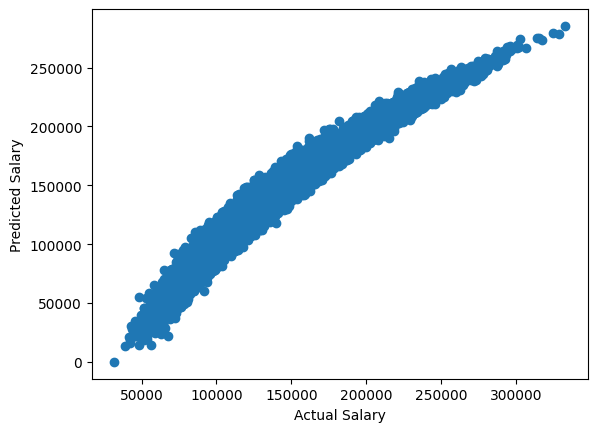

In [68]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.show()

In [69]:
# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the Random Forest model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regressor Performance:")
print(f"MAE: {mae_rf}")
print(f"MSE: {mse_rf}")
print(f"R2 Score: {r2_rf}")

Random Forest Regressor Performance:
MAE: 2489.8210386799997
MSE: 12466976.295500131
R2 Score: 0.9909653494135131


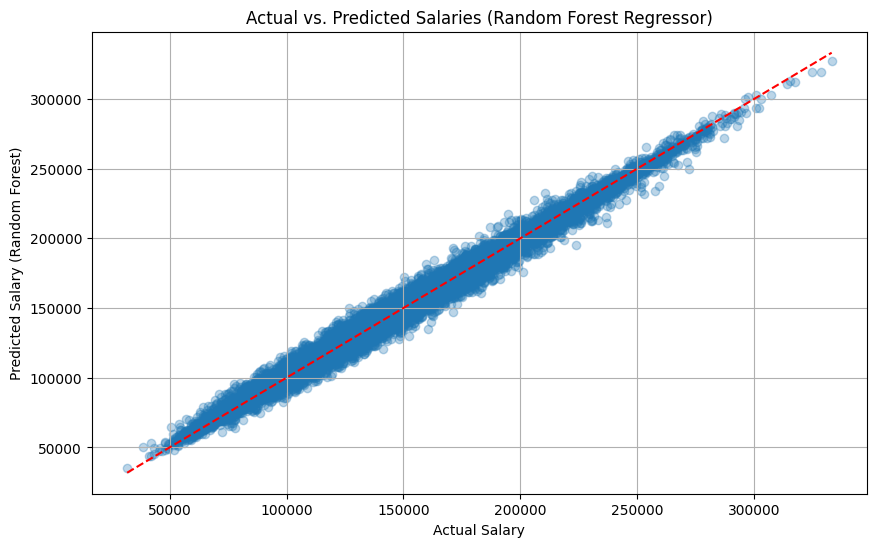

In [70]:
import matplotlib.pyplot as plt

# Visualize actual vs. predicted salaries for Random Forest
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary (Random Forest)")
plt.title("Actual vs. Predicted Salaries (Random Forest Regressor)")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--') # Perfect prediction line
plt.grid(True)
plt.show()

## Salary Prediction Function

In [71]:
import pandas as pd
import numpy as np

def predict_salary_from_input(
    experience_years: float,
    skills_count: int,
    education_level: str, # e.g., 'Bachelor', 'Master', 'PhD', 'High School'
    industry: str, # e.g., 'Healthcare', 'IT', 'Finance', 'Manufacturing', 'Media', 'Retail', 'Telecom', 'Education', 'Energy', 'Automotive', 'Construction'
    company_size: str, # 'Small', 'Medium', 'Large'
    location: str, # e.g., 'India', 'Australia', 'Singapore', 'Canada', 'Sweden', 'UK', 'USA', 'Germany'
    remote_work: str, # 'Yes', 'No', 'Hybrid'
    certifications: int,
    job_title: str # e.g., 'AI Engineer', 'Data Analyst', 'Software Engineer', 'Product Manager'
) -> float:
    """
    Predicts salary based on raw user inputs using the trained Random Forest model.

    Args:
        experience_years (float): Years of experience.
        skills_count (int): Number of skills.
        education_level (str): Education level.
        industry (str): Industry.
        company_size (str): Company size.
        location (str): Location.
        remote_work (str): Remote work preference.
        certifications (int): Number of certifications.
        job_title (str): Job title.

    Returns:
        float: Predicted salary.
    """

    # Get the column names from the training data X
    feature_columns = X.columns.tolist()

    # Create an empty DataFrame for the new input with all feature columns
    # Initialize all values to 0 (important for one-hot encoded features and dropped categories)
    input_df = pd.DataFrame(0, index=[0], columns=feature_columns)

    # Populate numerical features
    input_df['experience_years'] = experience_years
    input_df['skills_count'] = skills_count
    input_df['certifications'] = certifications

    # Populate one-hot encoded categorical features
    # The columns are created as 'category_value' (e.g., 'job_title_Data Analyst')
    # If 'drop_first=True' was used during get_dummies, some base categories won't have columns,
    # and their input will correctly result in all 0s for related one-hot columns.

    categorical_inputs = {
        'job_title': job_title,
        'education_level': education_level,
        'industry': industry,
        'company_size': company_size,
        'location': location,
        'remote_work': remote_work
    }

    for category, value in categorical_inputs.items():
        col_name = f'{category}_{value}'
        if col_name in feature_columns:
            input_df[col_name] = 1

    # Ensure the order of columns matches X for scaling and prediction
    # This is crucial for models like Linear Regression and for consistency.
    input_df = input_df[feature_columns]

    # Scale the input features using the trained scaler
    scaled_input = scaler.transform(input_df)

    # Make prediction using the Random Forest model
    predicted_salary = rf_model.predict(scaled_input)[0]

    return predicted_salary

### Try it out! Enter your details below to get a salary prediction:

In [72]:
# --- Demonstration (Simplified Input) ---
# Prompt user for years of experience, and use default values for other parameters

print("\nPlease enter your years of experience to get a salary prediction:")

exp = float(input("Years of Experience (e.g., 5.0): "))

# Using sensible default values for other parameters
# skills = 7 # Example: median skills_count is 10, using 7 as a moderate default
#edu = 'Bachelor' # Example: common education level
#ind = 'IT' # Example: common industry
#comp_size = 'Medium' # Example: common company size
#loc = 'USA' # Example: common location
#remote = 'No' # Example: common remote work status
#certs = 2 # Example: median certifications is 2
#job = 'Software Engineer' # Example: common job title

# Call the prediction function
try:
    predicted_salary = predict_salary_from_input(
        experience_years=exp,
        skills_count=skills,
        education_level=edu,
        industry=ind,
        company_size=comp_size,
        location=loc,
        remote_work=remote,
        certifications=certs,
        job_title=job
    )
    print(f"\nBased on {exp} years of experience (and default values for other factors), the predicted salary is: ${predicted_salary:,.2f}")
except KeyError as e:
    print(f"Error: A default categorical value was provided that is not recognized by the model. Please check the hardcoded defaults for: {e}.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")


Please enter your years of experience to get a salary prediction:
Years of Experience (e.g., 5.0): 4.0
An unexpected error occurred: name 'skills' is not defined


In [74]:
# ==============================
# 1. Import Libraries
# ==============================
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ==============================
# 2. Load Dataset
# ==============================
df = pd.read_csv('/job_salary_prediction_dataset.csv')

# ==============================
# 3. Select Required Columns
# ==============================
df = df[['experience_years', 'industry', 'salary']]

# ==============================
# 4. One-Hot Encoding
# ==============================
df = pd.get_dummies(df, columns=['industry'])

# Debug: print columns
print("Columns after encoding:")
print(df.columns)

# ==============================
# 5. Split Features & Target
# ==============================
X = df.drop('salary', axis=1)
y = df['salary']

# ==============================
# 6. Train-Test Split
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==============================
# 7. Feature Scaling
# ==============================
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==============================
# 8. Train Model
# ==============================
model = LinearRegression()
model.fit(X_train, y_train)

# ==============================
# 9. Model Evaluation
# ==============================
y_pred = model.predict(X_test)

print("\nModel Evaluation:")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# ==============================
# 10. User Input
# ==============================
exp = float(input("\nEnter Years of Experience: "))
industry_input = input("Enter Industry: ")

# ==============================
# 11. Prepare Input Data
# ==============================
# Create empty dataframe with same columns as X
input_data = pd.DataFrame(np.zeros((1, len(X.columns))), columns=X.columns)

# Set experience
input_data['experience_years'] = exp

# Handle industry
industry_col = 'industry_' + industry_input

if industry_col in input_data.columns:
    input_data[industry_col] = 1
else:
    print("⚠ Warning: Industry not found in dataset. Using default values.")

# ==============================
# 12. Scale Input
# ==============================
input_scaled = scaler.transform(input_data)

# ==============================
# 13. Predict Salary
# ==============================
predicted_salary = model.predict(input_scaled)

# ==============================
# 14. Output Result
# ==============================
print(f"\nEstimated Salary for {exp} years in {industry_input}: ₹{predicted_salary[0]:.2f}")

Columns after encoding:
Index(['experience_years', 'salary', 'industry_Consulting',
       'industry_Education', 'industry_Finance', 'industry_Government',
       'industry_Healthcare', 'industry_Manufacturing', 'industry_Media',
       'industry_Retail', 'industry_Technology', 'industry_Telecom'],
      dtype='object')

Model Evaluation:
MAE: 26586.105219108606
R2 Score: 0.18837810528149412

Enter Years of Experience: 4
Enter Industry: Healthcare

Estimated Salary for 4.0 years in Healthcare: ₹129544.45
